# OMCDE
### Opposition-based Multi-Stage Matrix-Based Competitive Differential Evolution

**Paper-to-code implementation · NumPy · Reproducible experiments**

**Authors of the paper:** Mohammad Sarhangzadeh, Shahryar Rahnamayan, and Doruk Oner.

This notebook implements the method in the supplied OMCDE paper. It is built for **understanding, experimenting with, and reusing** the optimizer on continuous, bounded minimization problems, rather than reproducing any reported CEC 2017 scores without their exact benchmark harness.

| Design feature | How it works |
|:---|:---|
| **Opposition-based initialization** | Generate `X` and `L + U − X`, then retain the full population with smaller total fitness |
| **Triplet competition** | Randomize candidates, rank each small group as best / medium / worst |
| **Stage-dependent mutation** | Competitive exploration → greedier global-best search after **75%** of the evaluation budget |
| **Matrix-based evolution** | All candidates mutate, cross over, and select using NumPy batches |
| **Adaptive controls and archive** | Learn `F` and `CR` from successful candidates; store displaced parents |
| **Linear population reduction** | Decrease the population from `18D` to `4` as evaluations are spent |

**Quick path:** Run all cells, inspect the Sphere result and convergence figure, then replace the objective with your own batched fitness function.

## 1. Algorithm at a glance

We minimize an objective $f(\mathbf{x})$ for $\mathbf{x}\in[L,U]^D$ and an evaluation budget of $FES_{\max}$.

**Pipeline**

`Initialize X and its opposition → select better complete population → sample F/CR from memories → create random ranked triplets → mutate according to stage → binomial crossover → select improved candidates → update archive and memories → reduce population → repeat`

For each triplet, let $b,m,w$ be the *best*, *medium*, and *worst* individuals, with individual-specific scaling factors $F_b,F_m,F_w$. Let $\Delta_r=r_1-r_2$, where the random vectors are sampled from the union of the current population and the external archive.

**Phase 1 — competitive search** ($FES\leq 0.75FES_{\max}$; paper Eqs. 2–4):

$$
\begin{aligned}
v_b &= b+F_b\Delta_r\\
v_m &= m+F_m(b-m)+F_m\Delta_r\\
v_w &= w+F_w(b-w)+F_w(m-w)
\end{aligned}
$$

**Phase 2 — greedy search** ($FES>0.75FES_{\max}$; Eqs. 12–14), using the global-best vector $g$:

$$
\begin{aligned}
v_b &= b+F_b(g-b)+F_b\Delta_r\\
v_m &= m+F_m(g-m)+F_m(b-m)+F_m\Delta_r\\
v_w &= w+F_w(g-w)+F_w(b-w)+F_w(m-w)
\end{aligned}
$$

The remaining algorithm uses binomial crossover, greedy parent–trial selection, improvement-weighted Lehmer updates, and population-size reduction.

## 2. Dependencies

Only **NumPy** is required for the optimizer; **Matplotlib** is used for plots. All optimization code is defined inside this notebook, so you can run it without cloning the entire repository. The same code is available as `omcde.py` for ordinary Python imports.

If dependencies are missing, install them once with `pip install numpy matplotlib`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

print("NumPy:", np.__version__)

NumPy: 2.3.5


## 3. OMCDE implementation

The following self-contained implementation closely follows the paper, with clearly documented decisions for underspecified edge cases:

- Fitness evaluations are counted **for both original and opposite populations**, unlike the single-count initialization in Algorithm 1.
- A minimum population of four is supported by temporarily borrowing companions to complete the last triplet, without re-evaluating those companions.
- Bound violations use **midpoint repair** by default (not specified in the paper).
- The external archive stores displaced parents after successful replacements, with uniform random pruning; both `F` and `CR` histories use improvement-weighted Lehmer updates.

The actual candidates are processed in batch arrays; there is **no Python loop over individuals**.

In [2]:
"""OMCDE: Opposition-based Multi-Stage Matrix-Based Competitive DE.

A NumPy implementation of the algorithm described by Sarhangzadeh,
Rahnamayan, and Oner. Optimization internals are vectorized over candidates.

Implementation decisions absent or inconsistent in the paper are documented
in the repository README and notebook.
"""

from dataclasses import dataclass
from time import perf_counter
from typing import Callable, Optional, Union

import numpy as np

Array = np.ndarray
BatchObjective = Callable[[Array], Array]


@dataclass
class OMCDEResult:
    """Optimization outcome and history (minimization)."""

    x: Array
    fun: float
    nfev: int
    nit: int
    elapsed_seconds: float
    history: dict
    final_population: Array
    final_fitness: Array

    def __repr__(self) -> str:
        return (
            f"OMCDEResult(fun={self.fun:.6g}, nfev={self.nfev}, "
            f"nit={self.nit}, elapsed_seconds={self.elapsed_seconds:.3f})"
        )


def _evaluate(objective: BatchObjective, candidates: Array) -> Array:
    """Evaluate a full batch; input (N, D) -> output (N,)."""
    values = np.asarray(objective(candidates), dtype=float).reshape(-1)
    if values.size != len(candidates):
        raise ValueError(
            "objective must map an (N, D) array to N fitness values; "
            f"received shape {values.shape} for N={len(candidates)}."
        )
    if not np.all(np.isfinite(values)):
        raise ValueError("objective returned NaN or infinite fitness values")
    return values


def _controls(
    rng: np.random.Generator, memory_f: Array, memory_cr: Array, size: int
) -> tuple[Array, Array]:
    """Sample per-individual SHADE-style F and CR vectors (Eq. 15)."""
    memory_indices = rng.integers(0, len(memory_f), size=size)
    f = memory_f[memory_indices] + 0.1 * rng.standard_cauchy(size)
    # Reject nonpositive Cauchy samples in batches; no candidate-by-candidate loop.
    invalid = f <= 0.0
    while np.any(invalid):
        f[invalid] = memory_f[memory_indices[invalid]] + 0.1 * rng.standard_cauchy(
            np.count_nonzero(invalid)
        )
        invalid = f <= 0.0
    f = np.minimum(f, 1.0)
    cr = np.clip(
        rng.normal(memory_cr[memory_indices], 0.1, size=size), 0.0, 1.0
    )
    return f, cr


def _weighted_lehmer(values: Array, improvements: Array) -> Optional[float]:
    """Improvement-weighted Lehmer mean (Eq. 16)."""
    denominator = np.dot(improvements, values)
    if denominator <= 0:
        return None
    return float(np.dot(improvements, values * values) / denominator)


def _random_differences(
    rng: np.random.Generator, population: Array, archive: Array, targets: Array
) -> Array:
    """Batch sample r1 != r2, both different from each target.

    Indices refer to the union of current population and external archive.
    Rank-skipping sampling avoids a per-individual rejection loop.
    """
    pool = np.concatenate((population, archive), axis=0)
    size = len(pool)
    # Population contains at least four members, so this is always possible.
    r1 = rng.integers(0, size - 1, size=targets.size)
    r1 += r1 >= targets
    low = np.minimum(r1, targets)
    high = np.maximum(r1, targets)
    r2 = rng.integers(0, size - 2, size=targets.size)
    r2 += r2 >= low
    r2 += r2 >= high
    return pool[r1] - pool[r2]


def _competitive_mutants(
    rng: np.random.Generator,
    population: Array,
    fitness: Array,
    factors: Array,
    archive: Array,
    global_best: Array,
    greedy: bool,
) -> Array:
    """Vectorized triplet competition and two-stage mutation (Eqs. 2-4, 12-14).

    When N is not divisible by 3, pad the final triplet with *companions*
    borrowed from other groups. Padded entries help rank candidates but do
    not receive another trial; each original candidate gets exactly one trial.
    """
    n, dim = population.shape
    shuffled = rng.permutation(n)
    remainder = n % 3
    padded = 0 if remainder == 0 else 3 - remainder
    if padded:
        full = n - remainder
        companions = rng.choice(shuffled[:full], size=padded, replace=False)
        shuffled = np.concatenate((shuffled, companions))

    eligible = np.concatenate((np.ones(n, bool), np.zeros(padded, bool)))
    groups = shuffled.reshape(-1, 3)
    eligible = eligible.reshape(-1, 3)
    # Each triplet is ranked by ascending fitness (best, medium, worst).
    order = np.argsort(fitness[groups], axis=1, kind="stable")
    ranked_ids = np.take_along_axis(groups, order, axis=1)
    eligible = np.take_along_axis(eligible, order, axis=1)

    individuals = population[ranked_ids]
    best, middle, worst = individuals[:, 0], individuals[:, 1], individuals[:, 2]
    f = factors[ranked_ids, None]  # (triplets, 3, 1)
    fb, fm, fw = f[:, 0], f[:, 1], f[:, 2]
    differences = _random_differences(
        rng, population, archive, ranked_ids.ravel()
    ).reshape(-1, 3, dim)

    if greedy:
        # Equations 12-14, with the global best broadcast over all triplets.
        vb = best + fb * (global_best - best) + fb * differences[:, 0]
        vm = (
            middle
            + fm * (global_best - middle)
            + fm * (best - middle)
            + fm * differences[:, 1]
        )
        vw = (
            worst
            + fw * (global_best - worst)
            + fw * (best - worst)
            + fw * (middle - worst)
        )
    else:
        # Equations 2-4: original TCDE-style competitive behavior.
        vb = best + fb * differences[:, 0]
        vm = middle + fm * (best - middle) + fm * differences[:, 1]
        vw = worst + fw * (best - worst) + fw * (middle - worst)

    mutated = np.stack((vb, vm, vw), axis=1)
    result = np.empty_like(population)
    result[ranked_ids[eligible]] = mutated[eligible]
    return result


def _repair_bounds(
    trial: Array, parent: Array, lower: Array, upper: Array, method: str
) -> Array:
    """Bound handling; midpoint is a documented implementation choice."""
    if method == "clip":
        return np.clip(trial, lower, upper)
    # Midpoint repair moves out-of-range coordinates halfway toward the
    # violated bound from their feasible parent's coordinate.
    trial = np.where(trial < lower, (lower + parent) / 2.0, trial)
    trial = np.where(trial > upper, (upper + parent) / 2.0, trial)
    return trial


def omcde(
    objective: BatchObjective,
    dim: int,
    bounds: Union[tuple[float, float], tuple[Array, Array]] = (-100.0, 100.0),
    *,
    max_evals: Optional[int] = None,
    population_size: Optional[int] = None,
    min_population_size: int = 4,
    archive_ratio: float = 1.4,
    memory_size: int = 6,
    stage_switch: float = 0.75,
    boundary_repair: str = "midpoint",
    seed: Optional[int] = None,
) -> OMCDEResult:
    """Minimize a batch objective using OMCDE.

    Args:
        objective: Vectorized objective: (N, dim) -> (N,) fitnesses.
        dim: Decision-variable count.
        bounds: Scalar (lower, upper), or length-dim bound vectors.
        max_evals: Total row evaluations; defaults to 10_000 * dim.
        population_size: Initial N, defaults to 18 * dim.
        min_population_size: Paper specifies 4; non-triplet sizes are supported.
        archive_ratio: Max archive size / current population size.
        memory_size: History length H.
        stage_switch: Fraction of total evaluations spent in Phase 1.
        boundary_repair: 'midpoint' (default) or 'clip'.
        seed: Random seed for repeatable independent runs.

    Important: Unlike Algorithm 1's FES=N_init line, both original and
    opposite initial candidate evaluations are charged to the budget.
    """
    if not isinstance(dim, (int, np.integer)) or dim < 1:
        raise ValueError("dim must be a positive integer")
    max_evals = 10_000 * dim if max_evals is None else int(max_evals)
    n_init = 18 * dim if population_size is None else int(population_size)
    n_min = int(min_population_size)
    if n_min < 4 or n_init < n_min:
        raise ValueError("require initial population >= minimum >= 4")
    if max_evals < 2 * n_init:
        raise ValueError("max_evals must be >= 2 * initial population (OBL)")
    if memory_size < 1 or archive_ratio < 0:
        raise ValueError("memory_size must be >= 1; archive_ratio >= 0")
    if not (0.0 < stage_switch < 1.0):
        raise ValueError("stage_switch must be between 0 and 1")
    if boundary_repair not in ("midpoint", "clip"):
        raise ValueError("boundary_repair must be 'midpoint' or 'clip'")
    lower = np.broadcast_to(np.asarray(bounds[0], dtype=float), (dim,)).copy()
    upper = np.broadcast_to(np.asarray(bounds[1], dtype=float), (dim,)).copy()
    if not (np.all(np.isfinite(lower)) and np.all(np.isfinite(upper))):
        raise ValueError("bounds must be finite")
    if np.any(lower >= upper):
        raise ValueError("each lower bound must be strictly below upper bound")

    start = perf_counter()
    rng = np.random.default_rng(seed)
    population = rng.uniform(lower, upper, size=(n_init, dim))
    opposition = lower + upper - population   # Eq. 10
    original_fitness = _evaluate(objective, population)
    opposition_fitness = _evaluate(objective, opposition)
    # Eq. 11 chooses the better complete population, not candidate-wise.
    if opposition_fitness.sum() < original_fitness.sum():
        population, fitness = opposition, opposition_fitness
    else:
        fitness = original_fitness
    nfev = 2 * n_init  # Account for both complete initial fitness evaluations.
    archive = np.empty((0, dim), dtype=float)
    memory_f = np.full(memory_size, 0.5)
    memory_cr = np.full(memory_size, 0.5)
    memory_slot = 0
    best_idx = int(np.argmin(fitness))
    global_best = population[best_idx].copy()
    global_fitness = float(fitness[best_idx])

    history = {
        "nfev": [nfev],
        "best_f": [global_fitness],
        "population_size": [len(population)],
        "diversity": [float(np.mean(np.std(population, axis=0)))],
        "phase": ["initialization"],
    }
    generation = 0
    while nfev < max_evals:
        # Eq. 18: shrink before generating the next generation.
        target_size = int(
            np.rint(n_init + (n_min - n_init) * (nfev / max_evals))
        )
        target_size = max(n_min, min(len(population), target_size))
        if target_size < len(population):
            keep = np.argsort(fitness)[:target_size]
            population, fitness = population[keep], fitness[keep]
        n = len(population)
        archive_limit = int(np.floor(archive_ratio * n))
        if len(archive) > archive_limit:
            selected = rng.choice(len(archive), size=archive_limit, replace=False)
            archive = archive[selected]

        factors, crossover_rates = _controls(rng, memory_f, memory_cr, n)
        greedy = nfev > stage_switch * max_evals
        mutants = _competitive_mutants(
            rng, population, fitness, factors, archive, global_best, greedy
        )

        # In a final partial generation, evaluate only the remaining budget.
        eval_count = min(n, max_evals - nfev)
        targets = (
            np.arange(n)
            if eval_count == n
            else rng.choice(n, size=eval_count, replace=False)
        )
        mask = rng.random((eval_count, dim)) < crossover_rates[targets, None]
        mandatory_dim = rng.integers(0, dim, size=eval_count)
        mask[np.arange(eval_count), mandatory_dim] = True
        parents = population[targets]
        trials = np.where(mask, mutants[targets], parents)
        trials = _repair_bounds(trials, parents, lower, upper, boundary_repair)
        trial_fitness = _evaluate(objective, trials)
        nfev += eval_count
        improved = trial_fitness < fitness[targets]
        success_ids = targets[improved]

        if len(success_ids):
            improvement = fitness[success_ids] - trial_fitness[improved]
            # Archive successful offspring's *replaced parents* (JADE convention).
            archive = np.concatenate((archive, population[success_ids].copy()))
            if len(archive) > archive_limit:
                selected = rng.choice(
                    len(archive), size=archive_limit, replace=False
                )
                archive = archive[selected]
            population[success_ids] = trials[improved]
            fitness[success_ids] = trial_fitness[improved]

            mean_f = _weighted_lehmer(factors[success_ids], improvement)
            mean_cr = _weighted_lehmer(crossover_rates[success_ids], improvement)
            if mean_f is not None:
                memory_f[memory_slot] = 0.5 * memory_f[memory_slot] + 0.5 * mean_f
            if mean_cr is not None:
                memory_cr[memory_slot] = 0.5 * memory_cr[memory_slot] + 0.5 * mean_cr
            memory_slot = (memory_slot + 1) % memory_size

        best_idx = int(np.argmin(fitness))
        if fitness[best_idx] < global_fitness:
            global_fitness = float(fitness[best_idx])
            global_best = population[best_idx].copy()
        generation += 1
        history["nfev"].append(nfev)
        history["best_f"].append(global_fitness)
        history["population_size"].append(n)
        history["diversity"].append(float(np.mean(np.std(population, axis=0))))
        history["phase"].append("greedy" if greedy else "competitive")

    return OMCDEResult(
        x=global_best,
        fun=global_fitness,
        nfev=nfev,
        nit=generation,
        elapsed_seconds=perf_counter() - start,
        history=history,
        final_population=population.copy(),
        final_fitness=fitness.copy(),
    )


## 4. Vectorized test functions

Each fitness function takes a matrix **`X.shape == (N, D)`** and returns an **`(N,)`** array. The minimum is at $\mathbf{x}=0$ for Sphere, Rastrigin, and Ackley, and at $\mathbf{x}=(1,\ldots,1)$ for Rosenbrock; each has minimum fitness $0$.

These are accessible smoke benchmarks — **not** the shifted/rotated CEC 2017 test functions from the paper.

In [3]:
def sphere(X):
    return np.sum(X**2, axis=1)


def rastrigin(X):
    d = X.shape[1]
    return 10.0 * d + np.sum(X**2 - 10.0 * np.cos(2 * np.pi * X), axis=1)


def ackley(X):
    d = X.shape[1]
    radial = np.sqrt(np.sum(X**2, axis=1) / d)
    cosine = np.sum(np.cos(2 * np.pi * X), axis=1) / d
    return -20 * np.exp(-0.2 * radial) - np.exp(cosine) + 20 + np.e


def rosenbrock(X):
    return np.sum(100.0 * (X[:, 1:] - X[:, :-1]**2)**2
                  + (1.0 - X[:, :-1])**2, axis=1)

# Rosenbrock's optimum is at x=(1,1,...,1), not at zero.
BENCHMARKS = {
    'Sphere': (sphere, (-5.0, 5.0)),
    'Rastrigin': (rastrigin, (-5.12, 5.12)),
    'Ackley': (ackley, (-5.0, 5.0)),
    'Rosenbrock': (rosenbrock, (-5.0, 5.0)),
}
print('Benchmarks available:', ', '.join(BENCHMARKS))

Benchmarks available: Sphere, Rastrigin, Ackley, Rosenbrock


## 5. First optimization: 10-dimensional Sphere

The paper's default population size is `18 × D`, and its archive / history / phase settings are built into the function. For a quick tutorial run we use a smaller budget than the paper's full `10,000 × D` setting. Change `max_evals` to `10_000 * D` when you want that full budget.

In [4]:
D = 10
result = omcde(
    sphere,
    dim=D,
    bounds=(-5.0, 5.0),
    max_evals=8_000,
    seed=42,
)

print(result)
print('Best objective:', f'{result.fun:.8e}')
print('Best vector:', np.array2string(result.x, precision=4))
print('Evaluations:', result.nfev)
print('Generations:', result.nit)
print('Final population:', len(result.final_population))

OMCDEResult(fun=8.59868e-12, nfev=8000, nit=170, elapsed_seconds=0.049)
Best objective: 8.59867602e-12
Best vector: [ 6.4578e-07  6.2111e-07 -2.4863e-06 -5.0084e-07 -7.4175e-07 -4.5104e-07
 -4.1181e-07  5.5279e-08  4.7400e-07  4.6087e-07]
Evaluations: 8000
Generations: 170
Final population: 4


## 6. Convergence and evolutionary diagnostics

The vertical line marks the paper's stage-switching threshold, $\lambda=0.75$. We also visualize population reduction and the standard deviation of candidate coordinates as a simple population-diversity indicator.

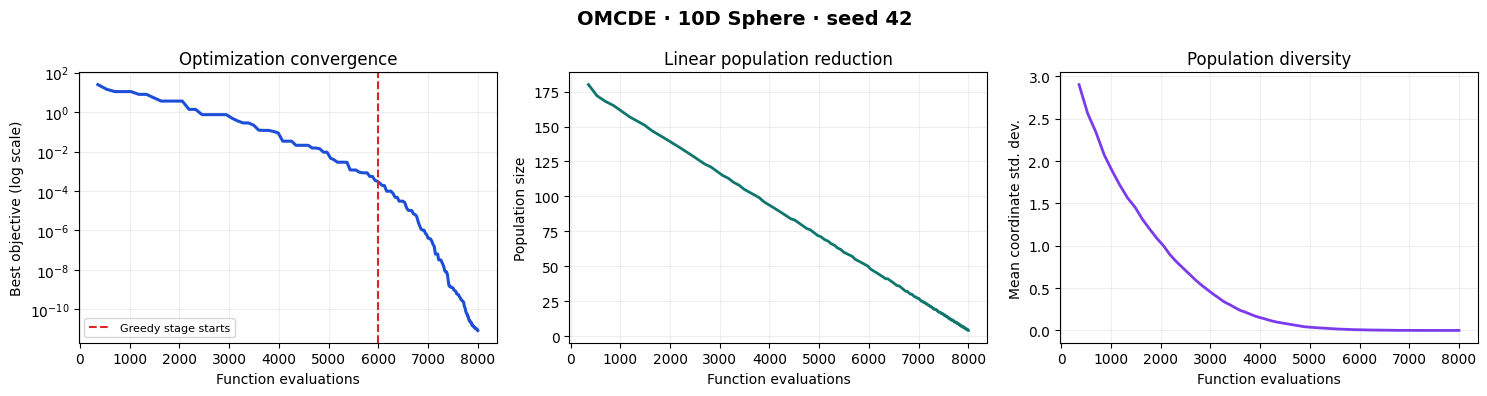

In [5]:
hist = result.history
fes = np.asarray(hist['nfev'])
quality = np.asarray(hist['best_f'])

fig, axs = plt.subplots(1, 3, figsize=(15, 4))

axs[0].semilogy(fes, np.maximum(quality, 1e-16), lw=2.2, color='#1d4ed8')
axs[0].axvline(0.75 * 8_000, color='#dc2626', ls='--', lw=1.5, label='Greedy stage starts')
axs[0].set(xlabel='Function evaluations', ylabel='Best objective (log scale)', title='Optimization convergence')
axs[0].legend(fontsize=8)

axs[1].plot(fes, hist['population_size'], color='#0f766e', lw=2)
axs[1].set(xlabel='Function evaluations', ylabel='Population size', title='Linear population reduction')

axs[2].plot(fes, hist['diversity'], color='#7c3aed', lw=2)
axs[2].set(xlabel='Function evaluations', ylabel='Mean coordinate std. dev.', title='Population diversity')

for ax in axs:
    ax.grid(alpha=0.2)
fig.suptitle('OMCDE · 10D Sphere · seed 42', fontsize=14, fontweight='bold')
fig.tight_layout()
plt.show()

## 7. Compare behavior on four different landscapes

We run once on each function with the **same dimensionality and evaluation budget**, then visualize their convergence. The functions have different numerical scales, so **compare the shapes of the curves**, not absolute scores across different functions.

In [6]:
results = {}
D_COMPARE = 8
BUDGET_COMPARE = 6_000

for name, (function, domain) in BENCHMARKS.items():
    run = omcde(
        function, dim=D_COMPARE, bounds=domain,
        max_evals=BUDGET_COMPARE, seed=42,
    )
    results[name] = run
    print(f'{name:12s} best={run.fun:12.5e}  evaluations={run.nfev:5d} '
          f'generations={run.nit:3d}')

Sphere       best= 7.06374e-13  evaluations= 6000 generations=150
Rastrigin    best= 2.59903e+00  evaluations= 6000 generations=150
Ackley       best= 2.96934e-06  evaluations= 6000 generations=150
Rosenbrock   best= 2.73359e+00  evaluations= 6000 generations=150


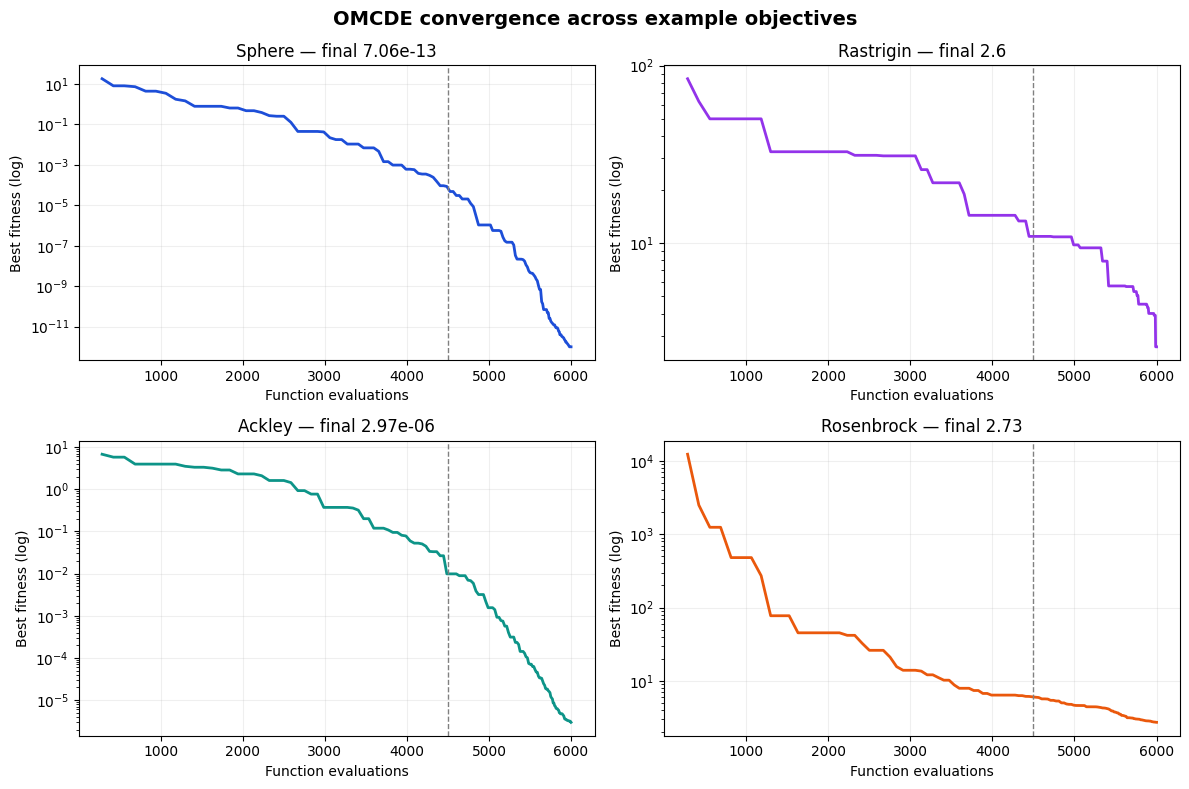

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
colors = ['#1d4ed8', '#9333ea', '#0d9488', '#ea580c']

for ax, (name, run), color in zip(axes.flat, results.items(), colors):
    h = run.history
    ax.semilogy(h['nfev'], np.maximum(h['best_f'], 1e-12), lw=2, color=color)
    ax.axvline(0.75 * BUDGET_COMPARE, color='gray', ls='--', lw=1)
    ax.set_title(f'{name} — final {run.fun:.3g}')
    ax.set_xlabel('Function evaluations')
    ax.set_ylabel('Best fitness (log)')
    ax.grid(alpha=0.2)
fig.suptitle('OMCDE convergence across example objectives', fontsize=14, fontweight='bold')
fig.tight_layout()
plt.show()

## 8. Stochastic variability over independent runs

Evolutionary methods are randomized; a single run is not a meaningful statistical evaluation. Below we run five independent seeds on the 8D Rastrigin function and print a quick mean and standard deviation. The paper's published CEC experiment instead uses **31 runs** on **D=30**, with **`FES_max = 10,000 × D`**.

In [8]:
seeds = [0, 1, 2, 3, 4]
scores = np.array([
    omcde(rastrigin, dim=8, bounds=(-5.12, 5.12),
          max_evals=6_000, seed=seed).fun
    for seed in seeds
])

print('Rastrigin — independent seeds:', seeds)
print('Final fitness values:', np.array2string(scores, precision=4))
print(f'Mean ± sample SD: {scores.mean():.6g} ± {scores.std(ddof=1):.6g}')

Rastrigin — independent seeds: [0, 1, 2, 3, 4]
Final fitness values: [4.8352 6.1084 5.246  3.0212 4.7882]
Mean ± sample SD: 4.79981 ± 1.12654


## 9. Use OMCDE on your own continuous objective

For your own problem, the only required part is the batch objective interface. Here is a weighted quadratic function whose known minimum is at $x_i = 1$. The bounds can be dimension-specific too: `bounds=(lower_vector, upper_vector)`.

**Important:** This code is for **box-constrained continuous minimization**. More general constraints would require a separate penalization or feasibility mechanism.

In [9]:
def custom_fitness(X):
    # batch of candidates -> one loss per candidate
    weights = np.linspace(0.5, 3.0, X.shape[1])
    return np.sum(weights * (X - 1.0)**2, axis=1)

custom = omcde(
    custom_fitness, dim=6,
    bounds=(np.full(6, -3.0), np.full(6, 4.0)),
    max_evals=5_000, seed=7,
)
print('Final objective:', custom.fun)
print('Best coordinates:', np.round(custom.x, 5))

Final objective: 7.870267683621584e-17
Best coordinates: [1. 1. 1. 1. 1. 1.]


## 10. Quick correctness checks

These basic assertions confirm the expected result shape, exact budget usage, monotonic best-so-far fitness, and maintained bounds. The repository additionally includes a `tests/` folder with unit tests for all six mutation formulas, repeatability, and the non-divisible-by-three edge case.

In [10]:
assert result.nfev == 8_000
assert result.x.shape == (10,)
assert len(result.history['nfev']) == result.nit + 1
assert np.all(np.diff(result.history['best_f']) <= 1e-12)
assert np.all(result.final_population >= -5.0)
assert np.all(result.final_population <= 5.0)
assert 'competitive' in result.history['phase']
assert 'greedy' in result.history['phase']
assert np.isclose(result.fun, sphere(result.x[None, :])[0])
print('All notebook smoke checks passed.')

All notebook smoke checks passed.


## 11. How to recreate the paper's CEC 2017 protocol

The experiments section specifies:

- **CEC 2017**: 29 functions, omitting **F2**; dimension **30**; domain $[-100,100]^{30}$.
- **31 independent runs** per function, with **`max_evals = 10_000 * 30`**.
- Report **error** $f(x_{best})-f(x^*)$, not raw shifted objective fitness; include means / standard deviations and appropriate cross-method statistical tests.

The optimizer already accepts the correct dimensionality, bounds and evaluation budget. To reproduce that table, connect the **exact official CEC 2017 objective implementation** using an adapter that accepts `(N, D)` and returns `(N,)`. Some CEC packages expose only single-vector evaluation; an adapter over rows works but its *objective evaluation* is not vectorized, so timing would not be comparable to a genuinely batched evaluator.

This notebook does **not** claim to reproduce Table I: the source paper does not unambiguously specify every archive, repair, and history-update edge case, and its pseudocode undercounts opposition evaluations.

## 12. Technical notes and attribution

**Faithfulness and explicit implementation decisions**

1. **Population-level OBL**: compare *sums* over two full populations; do not select the better of each individual/opposite pair.
2. **Function evaluations**: initializing both populations requires `2 × N_init` actual objective evaluations. We count both even though Algorithm 1 sets `FES = N_init`.
3. **Triplet grouping when `N % 3 != 0`**: borrow temporary companion individuals only for ranking. This is necessary because the paper also specifies `N_min = 4`.
4. **F and CR**: per-candidate memory samples, positive Cauchy F capped at 1, Gaussian CR clipped to [0,1]. Successful samples update a rotating memory slot using improvement-weighted Lehmer means and 50/50 smoothing.
5. **Archive and boundaries**: store replaced parents with random pruning, and midpoint-repair candidates that cross box boundaries. The paper does not fully prescribe these choices; alternate interpretations may yield different benchmarks.
6. **Strict budget**: the final generation may have fewer evaluations than the current population size, and only those candidates are considered for trial selection.

**Paper**: *OMCDE: Opposition-based Multi-Stage Matrix-Based Competitive Differential Evolution* — Mohammad Sarhangzadeh, Shahryar Rahnamayan, Doruk Oner. The paper's linked [GitHub repository](https://github.com/MSarhangzadeh/OMCDE-Optimization) can host this implementation. Add your preferred license and publication metadata before release.

## 13. Five full-budget benchmark experiments (D = 30)

This section presents **newly executed demonstrations**, distinct from the paper’s CEC 2017 experiments. The five **unshifted, unrotated** analytic test functions have a known best value of 0.

**Protocol:** 30 dimensions, 300,000 function evaluations per run, random seeds `0, 1, 2, 3, 4`, default paper parameters (`N_init=18D`, `N_min=4`, `H=6`, archive capacity `1.4N`, phase switch `0.75`). Each function uses its common canonical domain: Sphere `[-100,100]`, Rastrigin `[-5.12,5.12]`, Rosenbrock `[-5,10]`, Ackley `[-32.768,32.768]`, Griewank `[-600,600]`.

The values below were **measured**, not copied from the research paper.

| Function | Best | Mean ± SD | Median |
|:--|--:|--:|--:|
| Sphere | 5.899e-91 | 3.226e-88 ± 5.076e-88 | 8.533e-89 |
| Rastrigin | 1.705e-13 | 3.865e-13 ± 4.204e-13 | 2.274e-13 |
| Rosenbrock | 0.000e+00 | 0.000e+00 ± 0.000e+00 | 0.000e+00 |
| Ackley | 7.550e-15 | 7.550e-15 ± 0.000e+00 | 7.550e-15 |
| Griewank | 0.000e+00 | 0.000e+00 ± 0.000e+00 | 0.000e+00 |

Exact `0.0` reflects floating-point limits, not a mathematical proof of an exact global optimizer. Benchmarks are illustrative; five seeds do not establish statistical superiority to any competitor.

![OMCDE five-function D30 convergence](results/convergence_d30.svg)

![OMCDE method overview](results/omcde_workflow.svg)


In [11]:
# Five D=30 analytic benchmarks, 5 independent seeds, full 300k-evaluation budget.
# This cell is reproducible and can be run independently of run_benchmarks.py.

def griewank(X):
    return 1.0 + np.sum(X**2, axis=1) / 4000.0 - np.prod(
        np.cos(X / np.sqrt(np.arange(1, X.shape[1] + 1))), axis=1
    )

BENCHMARKS_30 = {
    'Sphere': (sphere, (-100.0, 100.0)),
    'Rastrigin': (rastrigin, (-5.12, 5.12)),
    'Rosenbrock': (rosenbrock, (-5.0, 10.0)),
    'Ackley': (ackley, (-32.768, 32.768)),
    'Griewank': (griewank, (-600.0, 600.0)),
}

D_FULL, BUDGET_FULL = 30, 300_000
full_runs = {}
for name, (objective, search_bounds) in BENCHMARKS_30.items():
    full_runs[name] = [
        omcde(objective, D_FULL, search_bounds,
              max_evals=BUDGET_FULL, seed=seed)
        for seed in range(5)
    ]
    values = np.asarray([r.fun for r in full_runs[name]])
    print(f"{name:12s}  best={values.min():.4e}  "
          f"mean={values.mean():.4e}  SD={values.std(ddof=1):.4e}")


Sphere        best=5.8995e-91  mean=3.2255e-88  SD=5.0764e-88


Rastrigin     best=1.7053e-13  mean=3.8654e-13  SD=4.2041e-13


Rosenbrock    best=0.0000e+00  mean=0.0000e+00  SD=0.0000e+00


Ackley        best=7.5495e-15  mean=7.5495e-15  SD=0.0000e+00


Griewank      best=0.0000e+00  mean=0.0000e+00  SD=0.0000e+00


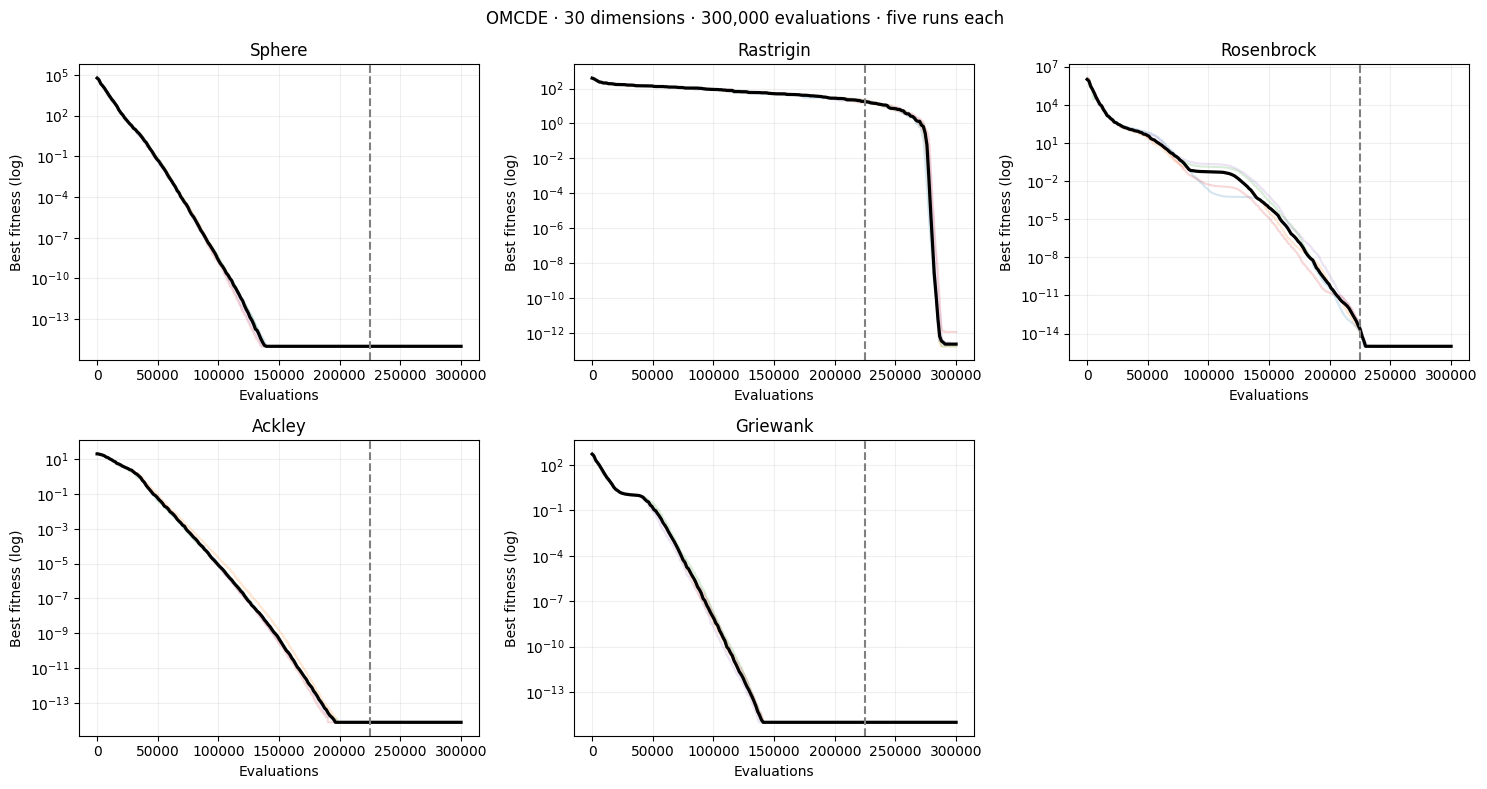

In [12]:
# Show the five landscapes' best-so-far fitness (median and individual seeds).
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (name, runs) in zip(axes.flat, full_runs.items()):
    for r in runs:
        ax.semilogy(r.history['nfev'], np.maximum(r.history['best_f'], 1e-15), alpha=0.18)
    x = np.linspace(0, BUDGET_FULL, 201)
    interpolated = [np.interp(x, r.history['nfev'], r.history['best_f']) for r in runs]
    ax.semilogy(x, np.maximum(np.median(interpolated, axis=0), 1e-15),
                color='black', linewidth=2.3, label='Median')
    ax.axvline(.75 * BUDGET_FULL, linestyle='--', color='gray')
    ax.set(title=name, xlabel='Evaluations', ylabel='Best fitness (log)')
    ax.grid(alpha=.2)
axes.flat[-1].axis('off')
fig.suptitle('OMCDE · 30 dimensions · 300,000 evaluations · five runs each')
plt.tight_layout()
plt.show()
